### **Task 3 – SVD based decoupling of MIMO channel**

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(3)

M = 4                       # 4 transmit and 4 receive antennas
noise_var = 1
Pt_values = [1, 2, 5, 10]   # total transmit power (W)
num_channels = 1000

# Achievable rate of the parallel channels
def rate(lam, P):
    return np.sum(np.log2(1 + P * lam / noise_var))

# Waterfilling algorithm to allocate power across parallel channels
def waterfilling(lam, Pt):
    k = len(lam)                  
    while True:
        mu = (Pt + np.sum(noise_var / lam[:k])) / k
        P = mu - noise_var / lam[:k]
        if P[-1] > 0:               
            break
        k = k - 1                           
    P_all = np.zeros(len(lam))
    P_all[:k] = P
    return P_all

rate_equal = np.zeros(len(Pt_values))
rate_inversion = np.zeros(len(Pt_values))
rate_best = np.zeros(len(Pt_values))
rate_waterfill = np.zeros(len(Pt_values))

for n in range(num_channels):
    # Rayleigh MIMO channel, each entry CN(0,1)
    H = (rng.standard_normal((M, M)) + 1j * rng.standard_normal((M, M))) / np.sqrt(2)
    U, S, Vh = np.linalg.svd(H)
    lam = S ** 2

    for j in range(len(Pt_values)):
        Pt = Pt_values[j]

        # (a) Equal power
        P = np.ones(M) * Pt / M
        rate_equal[j] += rate(lam, P)

        # (b) Channel inversion: P_i proportional to 1/lambda_i
        P = (1 / lam) * Pt / np.sum(1 / lam)
        rate_inversion[j] += rate(lam, P)

        # (c) All power to the best eigenmode
        P = np.array([Pt, 0, 0, 0])
        rate_best[j] += rate(lam, P)

        # (d) Waterfilling
        P = waterfilling(lam, Pt)
        rate_waterfill[j] += rate(lam, P)

# Average over the channel realisations
rate_equal /= num_channels
rate_inversion /= num_channels
rate_best /= num_channels
rate_waterfill /= num_channels

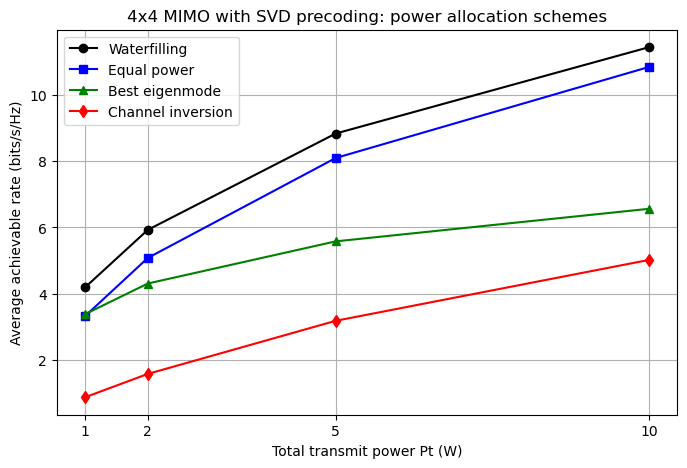

In [2]:
plt.figure(figsize=(8, 5))
plt.plot(Pt_values, rate_waterfill, 'k-o', label='Waterfilling')
plt.plot(Pt_values, rate_equal, 'b-s', label='Equal power')
plt.plot(Pt_values, rate_best, 'g-^', label='Best eigenmode')
plt.plot(Pt_values, rate_inversion, 'r-d', label='Channel inversion')
plt.xlabel('Total transmit power Pt (W)')
plt.ylabel('Average achievable rate (bits/s/Hz)')
plt.title('4x4 MIMO with SVD precoding: power allocation schemes')
plt.xticks(Pt_values)
plt.grid(True)
plt.legend()
plt.show()